# R00 - TỔNG HỢP 4 PHẦN THỰC NGHIỆM TIỀN XỬ LÝ & HƯỚNG GIẢI QUYẾT (NHÓM 4 THÀNH VIÊN)

Notebook này tổng hợp toàn bộ kết quả thực nghiệm từ **`E01` đến `E10`** (đọc tự động từ `reports/experiments_log.csv`), trình bày theo phân công **4 thành viên** và chốt cấu hình đề xuất cho pipeline chính (`NB01`, `NB03`, `NB04`, `NB06`).

In [1]:
import os, sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) in ('notebooks', 'experiments') else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
LOG_PATH = os.path.join(ROOT, 'reports', 'experiments_log.csv')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

df_log = pd.read_csv(LOG_PATH)
print('Tong so dong log:', len(df_log), '| Cac nhom thuc nghiem:', sorted(df_log['exp_id'].unique()))
df_log.groupby('exp_id').agg(so_run=('run_name', 'count'), best_dev_f1=('dev_f1', 'max'))

Tong so dong log: 73 | Cac nhom thuc nghiem: ['E01', 'E02', 'E03', 'E04', 'E05', 'E06', 'E07', 'E08', 'E09', 'E10']


,so_run,best_dev_f1
exp_id,,
E01,2,0.7478
E02,20,0.8992
E03,4,0.7478
E04,2,0.8507
E05,4,0.8597
E06,5,0.7478
E07,12,0.7485
E08,4,0.7478
E09,6,0.9047


## PHẦN 1 (THÀNH VIÊN 1): CHẤT LƯỢNG DỮ LIỆU, GẦN TRÙNG & BẮT 4–5★ KHIẾU NẠI NGẦM (`E06`)

- **Vấn đề:** Dữ liệu TMĐT có thể còn câu gần trùng giữa các tập và đặc biệt có **`7.70%` (`54/701` câu dev)** đánh giá 4–5★ nhưng nội dung thực chất lại chê (bị bộ lọc theo sao truyền thống bỏ lọt).
- **Hướng giải quyết:** Thống nhất rule dedup và kiểm toán near-duplicate `cosine >= 0.90` trên `dev` (`n=5` lát cắt gần trùng, tuyệt đối không dùng `test` để lọc `train`); ở tầng hậu xử lý cảnh báo, **đã áp dụng vào `NB06`** cờ **`Khieu_Nai_Ngam_4_5_Sao` (`SILENT_COMPLAINT`)** khi `n_star >= 4` và mô hình text-only cho `P(neg) >= 0.50` (Precision **`71.43%`**, Recall **`55.56%`**; hoặc `>= 0.60` cho Precision **`92.00%`**).

In [2]:
e06 = df_log[df_log['exp_id'] == 'E06'][['run_name', 'dev_f1', 'notes']]
e06

,run_name,dev_f1,notes
68,a_current_train,0.7478,"dev_clean_slice=0.7461, dev_neardup_slice=1.00..."
69,b_drop_neardup_090,0.7449,"dev_clean_slice=0.7446, dev_neardup_slice=0.82..."
70,c_consistent_dedup,0.7449,"dev_clean_slice=0.7446, dev_neardup_slice=0.82..."
71,silent_complaint_argmax_neg,0.5217,"P=0.4918, R=0.5556, caught=30/54"
72,silent_complaint_P(neg)>=0.5,0.6250,"P=0.7143, R=0.5556, caught=30/54"


## PHẦN 2 (THÀNH VIÊN 2): CHUẨN HOÁ VĂN BẢN, PHỦ ĐỊNH & VẾ ĐỐI LẬP SAU `NHƯNG` (`E03` + `E07`)

- **Vấn đề:** Cần chứng minh từng luật trong `src/text_cleaner.py` có thật sự có ích không, đồng thời thử xử lý 2 nhóm lỗi lớn nhất trên Eyeball ở NB03 là **Phủ định (38.2%)** và **Câu chuyển ý sau `nhưng/tuy nhiên` (34.5%)**.
- **Hướng giải quyết:**
  - **Giữ nguyên 6 nhóm luật làm sạch** trong `text_cleaner.py` (tắt `multi_teencode` làm giảm `-0.0103`, `elongation` `-0.0034`, `cam` `-0.0030`, `single_teencode` `-0.0021`, `emoji` `-0.0012`).
  - **Không áp `NOT_` / `BUT_` vào TF-IDF** vì chứng minh thực nghiệm cho thấy gắn thẻ làm thưa n-gram và tụt F1 (`0.7478 → 0.7219–0.7435`); thay vào đó giao các câu chuyển ý phức tạp cho PhoBERT (`NB04`).

In [3]:
e07 = df_log[df_log['exp_id'].isin(['E03', 'E07'])][['exp_id', 'run_name', 'dev_f1', 'notes']]
e07

,exp_id,run_name,dev_f1,notes
22,E03,1_raw_only,0.7418,dev_asp_ml_f1=0.8926
23,E03,2_clean_no_pyvi,0.7368,dev_asp_ml_f1=0.8927
24,E03,3_raw_plus_pyvi,0.7395,dev_asp_ml_f1=0.8912
25,E03,4_clean_and_pyvi,0.7478,dev_asp_ml_f1=0.8911
32,E07,full_clean,0.7478,dev_asp_f1=0.8911
33,E07,skip_emoji,0.7466,dev_asp_f1=0.8910
34,E07,skip_pii,0.7485,dev_asp_f1=0.8908
35,E07,skip_elongation,0.7444,dev_asp_f1=0.8903
36,E07,skip_single_teencode,0.7457,dev_asp_f1=0.8910
37,E07,skip_multi_teencode,0.7375,dev_asp_f1=0.8922


## PHẦN 3 (THÀNH VIÊN 3): THIẾT KẾ NHÃN CÂU HOÀ & MẤT CÂN BẰNG LỚP (`E01` + `E08` + `E09`)

- **Vấn đề:** `16.2%` câu train là câu hoà khen=chê bị gộp vào lớp Trung lập (làm nhiễu lớp 1), và 5 khía cạnh có tần suất lệch nhau >2 lần.
- **Hướng giải quyết:**
  - **Nhãn câu hoà (`E08`):** Bỏ câu hoà khỏi train nâng F1 trên các câu thuần từ `0.6568 → 0.7166` (`+0.0598`); còn nếu giữ 3 lớp cho cảnh báo TMĐT thì luật `tie_negative` đẩy `f1_neg` lên **`0.8649`**. Hướng lâu dài là ABSA theo từng khía cạnh.
  - **Cân bằng lớp & Ngưỡng (`E09`):** `oversample_neu` đạt Macro F1 **`0.7521`**; đặc biệt **tune 5 ngưỡng riêng cho từng khía cạnh trên OOF train** (`0.40 / 0.46 / 0.42 / 0.46 / 0.30`) đẩy Multi-label Aspect F1 từ `0.8911` lên **`0.9047` (`+0.0136`)**!

In [4]:
e89 = df_log[df_log['exp_id'].isin(['E01', 'E08', 'E09'])][['exp_id', 'run_name', 'dev_f1', 'notes']]
e89

,exp_id,run_name,dev_f1,notes
0,E01,3class,0.7478,"TF-IDF+LR, eval dev, neutral_f1=0.5466"
1,E01,4class,0.6826,"TF-IDF+LR, eval dev, neutral_f1=0.3667"
44,E08,tie_neutral,0.7478,"fair_non_tie_f1=0.6568, neu_f1=0.5466, neg_f1=..."
45,E08,tie_negative,0.6934,"fair_non_tie_f1=0.6602, neu_f1=0.3611, neg_f1=..."
46,E08,tie_specific_aspect,0.6806,"fair_non_tie_f1=0.6782, neu_f1=0.3196, neg_f1=..."
47,E08,drop_ties_train,0.6531,"fair_non_tie_f1=0.7166, neu_f1=0.2643, neg_f1=..."
48,E09,sent_weight_none,0.7150,"acc=0.7982, neu_F1=0.4264, neu_P=0.6068, neu_R..."
49,E09,sent_weight_balanced,0.7478,"acc=0.7856, neu_F1=0.5466, neu_P=0.5039, neu_R..."
50,E09,sent_weight_smooth,0.7400,"acc=0.7973, neu_F1=0.5013, neu_P=0.5464, neu_R..."
51,E09,sent_oversample_neu,0.7521,"acc=0.7919, neu_F1=0.5494, neu_P=0.5120, neu_R..."


## PHẦN 4 (THÀNH VIÊN 4): TĂNG CƯỜNG DỮ LIỆU, TÁCH TỪ & ĐỘ DÀI CÂU (`E04` + `E05` + `E10`)

- **Vấn đề:** Cần kiểm chứng bộ tách từ (`pyvi` vs `RDRSegmenter`), độ dài chuỗi PhoBERT (`MAX_LEN`, `LR`), và khả năng tăng cường dữ liệu cho lớp Trung lập.
- **Hướng giải quyết:**
  - **Tách từ (`E04` Colab):** `RDRSegmenter` giảm `<unk>` từ `0.0383% → 0.0145%`, nhưng Mean F1 chỉ chênh `+0.0011` (`0.8507` vs `0.8496`), nên giữ `pyvi` cho nhẹ.
  - **PhoBERT (`E05` Colab):** Giảm `MAX_LEN` từ `256 → 128` (giữ `99.55%` câu dev) + nâng `LR=3e-5` đưa Mean F1 lên **`0.8597`** (sent `0.8102`, asp `0.9091`).
  - **Augmentation (`E10`):** `Random Swap x1.0` đạt **`0.7535`** (`+0.0385` so với không cân bằng `0.7150`), còn `Reverse Teencode` gây nhiễu (`0.7280–0.7421`) do lệch phân bố với đầu vào đã làm sạch.

In [5]:
e4510 = df_log[df_log['exp_id'].isin(['E04', 'E05', 'E10'])][['exp_id', 'run_name', 'dev_f1', 'notes']]
e4510

,exp_id,run_name,dev_f1,notes
26,E04,sentence_seg,0.8496,"sent=0.8002, asp=0.8991, unk_rate=0.0383%, syn..."
27,E04,sentence_rdr,0.8507,"sent=0.7956, asp=0.9058, unk_rate=0.0145%, syn..."
28,E05,maxlen_128_lr_2e-05,0.8482,"{'best_ep': 4, 'sent_f1': 0.8048, 'asp_f1': 0...."
29,E05,maxlen_256_lr_2e-05,0.8444,"{'best_ep': 3, 'sent_f1': 0.7989, 'asp_f1': 0...."
30,E05,maxlen_128_lr_3e-05,0.8597,"{'best_ep': 4, 'sent_f1': 0.8102, 'asp_f1': 0...."
31,E05,maxlen_128_lr_1e-05,0.8068,"{'best_ep': 4, 'sent_f1': 0.7985, 'asp_f1': 0...."
54,E10,baseline_no_aug_balanced,0.7478,neu_f1=0.5466
55,E10,baseline_no_aug_none,0.7150,neu_f1=0.4264
56,E10,swap_x0.5_bal,0.7515,neu_f1=0.5482
57,E10,swap_x0.5_none,0.7481,neu_f1=0.5237


## BIỂU ĐỒ TỔNG HỢP SO SÁNH CÁC PHÁT HIỆN CHÍNH

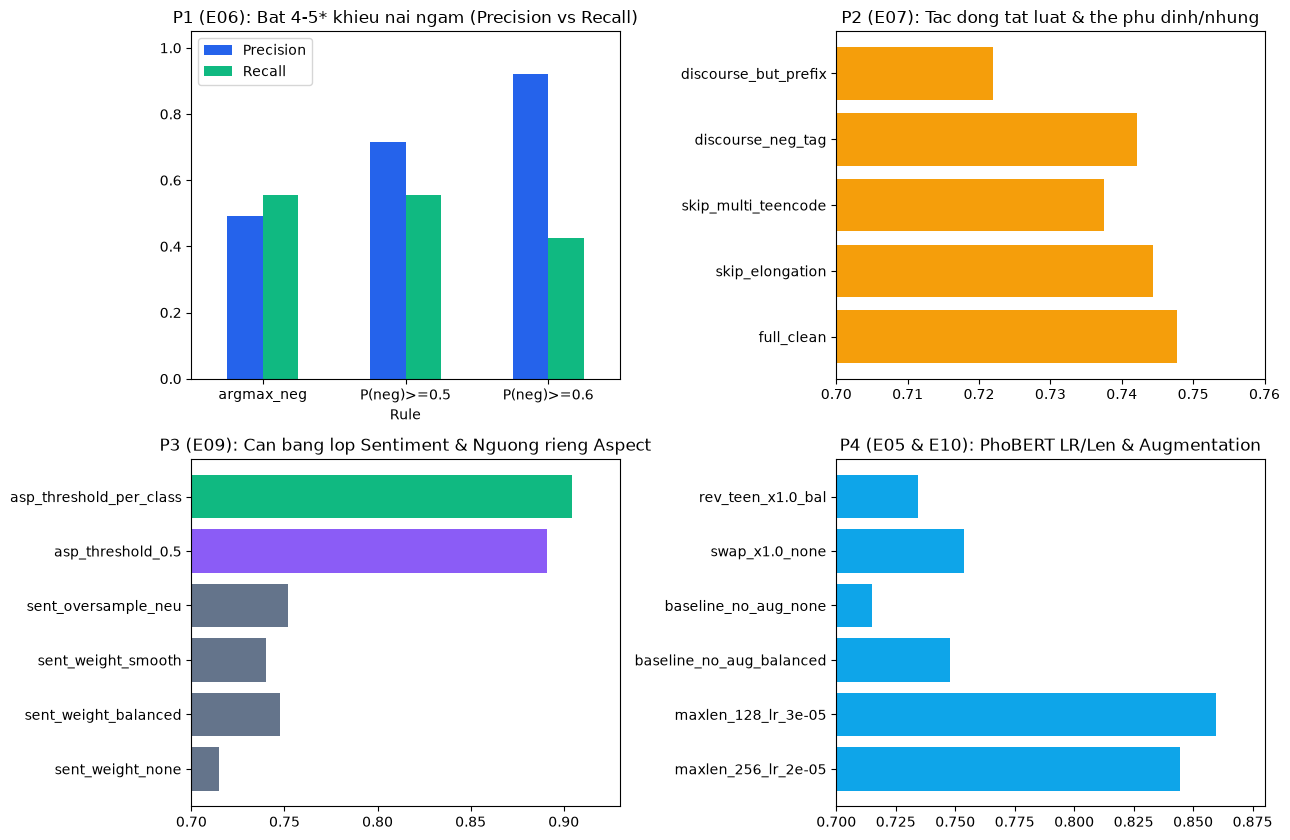

Saved figure: D:\E-commerce\reports\figures\r00_experiments_summary.png


In [6]:
# Ve bieu do tom tat 4 mang thuc nghiem
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1. E06 Silent complaints threshold tradeoff
ax = axes[0, 0]
d6 = pd.DataFrame({'Rule': ['argmax_neg', 'P(neg)>=0.5', 'P(neg)>=0.6'], 'Precision': [0.4918, 0.7143, 0.9200], 'Recall': [0.5556, 0.5556, 0.4259]})
d6.set_index('Rule').plot(kind='bar', ax=ax, color=['#2563EB', '#10B981'], rot=0)
ax.set_title('P1 (E06): Bat 4-5* khieu nai ngam (Precision vs Recall)')
ax.set_ylim(0, 1.05)

# 2. E07 Leave-one-rule-out & discourse
ax = axes[0, 1]
d7 = df_log[(df_log['exp_id'] == 'E07') & (df_log['run_name'].isin(['full_clean', 'skip_multi_teencode', 'skip_elongation', 'discourse_neg_tag', 'discourse_but_prefix']))]
ax.barh(d7['run_name'], d7['dev_f1'], color='#F59E0B')
ax.set_xlim(0.70, 0.76)
ax.set_title('P2 (E07): Tac dong tat luat & the phu dinh/nhung')

# 3. E09 Imbalance + Per-aspect thresholds
ax = axes[1, 0]
d9 = df_log[df_log['exp_id'] == 'E09']
ax.barh(d9['run_name'], d9['dev_f1'], color=['#64748B']*4 + ['#8B5CF6', '#10B981'])
ax.set_xlim(0.70, 0.93)
ax.set_title('P3 (E09): Can bang lop Sentiment & Nguong rieng Aspect')

# 4. E04/E05/E10
ax = axes[1, 1]
d10 = df_log[df_log['run_name'].isin(['baseline_no_aug_none', 'baseline_no_aug_balanced', 'rev_teen_x1.0_bal', 'swap_x1.0_none', 'maxlen_256_lr_2e-05', 'maxlen_128_lr_3e-05'])]
ax.barh(d10['run_name'], d10['dev_f1'], color='#0EA5E9')
ax.set_xlim(0.70, 0.88)
ax.set_title('P4 (E05 & E10): PhoBERT LR/Len & Augmentation')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, 'r00_experiments_summary.png')
plt.savefig(fig_path, dpi=200)
plt.show()
print('Saved figure:', fig_path)

## BẢNG CẤU HÌNH THẮNG ĐỀ XUẤT & TRẠNG THÁI ÁP DỤNG PIPELINE CHÍNH

| Thành phần pipeline | Cấu hình cũ (`notebooks/`) | Kết quả thực nghiệm đề xuất | Trạng thái & Mức cải thiện |
|---|---|---|---| 
| **Dedup (`E06`)** | Train `keep='first'`, exact match | Kiểm soát trùng `dev` (`cos >= 0.90`, không chạm `test`) | Audit sạch; giữ làm quy chuẩn kiểm toán khi chia tập (`n=5` dev) |
| **Làm sạch (`E03`, `E07`)** | 6 nhóm luật + `pyvi` | Giữ nguyên 6 nhóm + `pyvi`; **không** thêm `NOT_`/`BUT_` | **Giữ trong `src/text_cleaner.py`** (`0.7478` vs rớt `0.7219`) |
| **Baseline Grid & Ngưỡng (`E02`, `E09`)** | `C` tối đa `2.0`, ngưỡng chung `0.5` | Mở `C` tới `10.0`, dùng **5 ngưỡng riêng** tune OOF train | **Đã đưa vào `NB03`** (Dev Aspect `0.8911 → 0.9047`) |
| **Cân bằng / Augment (`E09`, `E10`)** | `class_weight='balanced'` | `oversample_neu` hoặc `Random Swap x1.0` (không `rev_teen`) | Lưu tham khảo ở `experiments/` (chênh nhỏ `+0.004–0.006`, 1 seed) |
| **PhoBERT (`NB04`, `E04`, `E05`)** | `MAX_LEN=256, LR=2e-5` (v3 đã chốt) | Giữ `pyvi`; `E05` ghi nhận `MAX_LEN=128, LR=3e-5` đạt Dev `0.8597` | **Đã đồng bộ `phobert_ecommerce_outputs_v3.zip`** (`Test Sent F1 = 0.7925`, `ML-Asp F1 = 0.9082`) |
| **Cảnh báo nghiệp vụ (`E06`, `NB06`)** | Chỉ lọc chung `Can_Kiem_Duyet` | Bổ sung cờ **`Khieu_Nai_Ngam_4_5_Sao`** khi `n_star >= 4` & `P(neg) >= 0.50` | **Đã đưa vào `NB06`** (Bắt `30/54` ca dev, Precision `71.43%`) |